# 06 · Synthesis: a mechanistic map of when codes mix and when they disentangle (Project 2)

Collects the final (full-run) results of notebooks 01–05 into one figure and a table of testable predictions.
Panel A is recomputed analytically; the other panels are re-drawn from the saved JSONs.

In [1]:
import os, sys, json, time
import numpy as np
import torch
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath(".."))
from mixdis import data, models, metrics, dendrite, rnn
from mixdis.utils import save_json, load_json, set_threads

# FAST=1 -> tiny smoke-test run (minutes). Unset/0 -> full experiment.
FAST = os.environ.get("FAST", "0") == "1"
set_threads()
RES = os.path.abspath("../results"); os.makedirs(RES, exist_ok=True)
FIG = os.path.join(RES, "figures"); os.makedirs(FIG, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})
def savefig(name):
    plt.savefig(os.path.join(FIG, name + ".png"), bbox_inches="tight", dpi=200)
    plt.savefig(os.path.join(FIG, name + ".pdf"), bbox_inches="tight")
print("FAST mode:", FAST, "| torch", torch.__version__, "| threads", torch.get_num_threads())

FAST mode: False | torch 2.14.1+cu130 | threads 1


In [2]:
def J(n):
    p = os.path.join(RES, n); return load_json(p) if os.path.exists(p) else None
d1, d2, d3, d4, d5 = [J(f) for f in ["nb01_energy.json", "nb02_statistics_gd.json", "nb03_task_demands.json",
                                     "nb04_regions_celltypes.json", "nb05_single_neurons.json"]]
print("available:", [n for n, d in zip(["01", "02", "03", "04", "05"], [d1, d2, d3, d4, d5]) if d])

available: ['01', '02', '03', '04', '05']


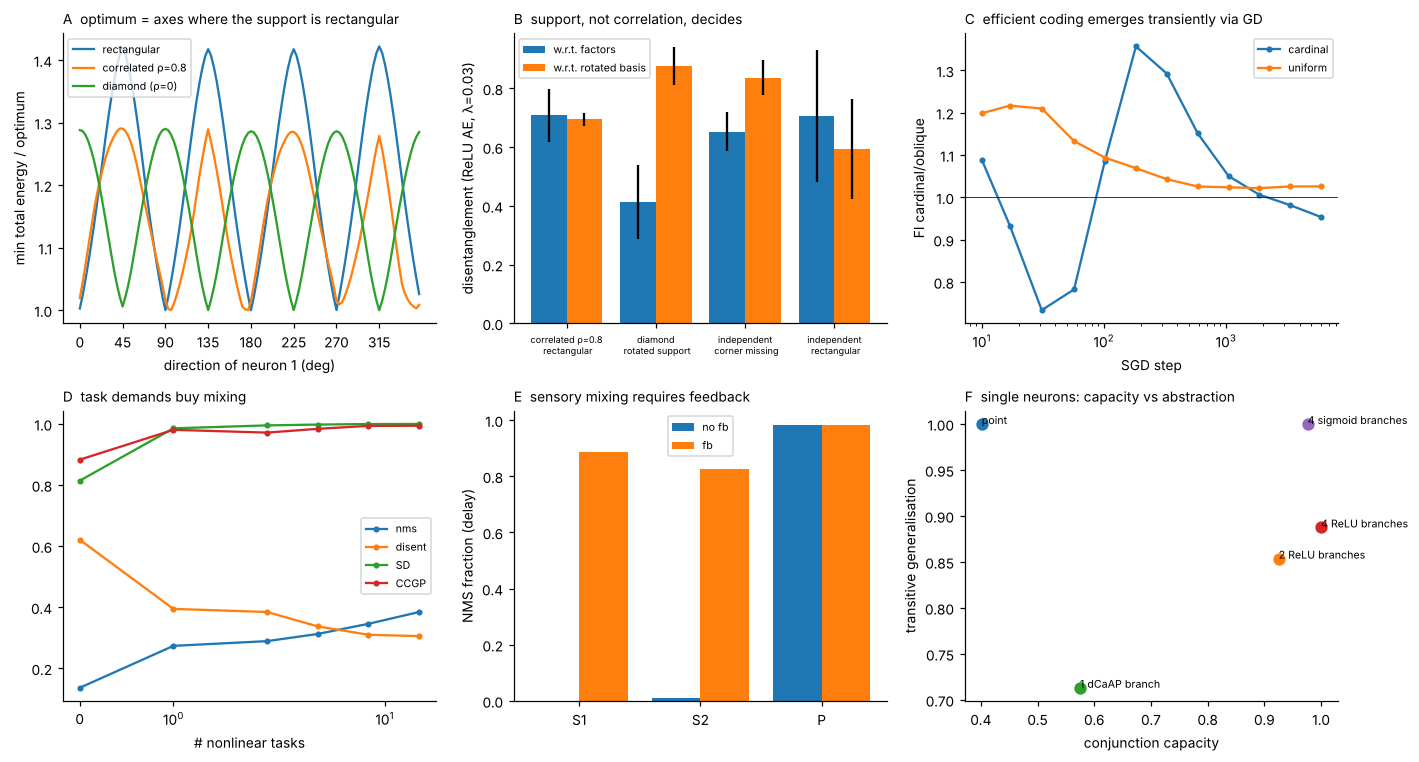

In [3]:
fig, axs = plt.subplots(2, 3, figsize=(13, 7))
ax = axs[0, 0]
# recompute the 1-D energy profile analytically (cheap): best partner for each first direction
rng = np.random.default_rng(0); NA = 120
ang = np.linspace(0, 2 * np.pi, NA, endpoint=False); U = np.stack([np.cos(ang), np.sin(ang)], 1)
for nm, kw in [("rectangular", dict()), ("correlated ρ=0.8", dict(corr=0.8)), ("diamond (ρ=0)", dict(support="diamond"))]:
    F = data.sample_factors(20000, 2, rng=rng, **kw); P = F @ U.T; e1 = ((P - P.min(0)) ** 2).mean(0)
    prof = []
    for i in range(NA):
        c = [e1[i] + e1[j] + (np.linalg.inv(U[[i, j]]) ** 2).sum() for j in range(NA) if abs(np.linalg.det(U[[i, j]])) > 0.05]
        prof.append(min(c))
    prof = np.array(prof); ax.plot(np.degrees(ang), prof / prof.min(), label=nm)
ax.set_xlabel("direction of neuron 1 (deg)"); ax.set_ylabel("min total energy / optimum"); ax.legend(fontsize=7)
ax.set_xticks([0, 45, 90, 135, 180, 225, 270, 315])
ax.set_title("A  optimum = axes where the support is rectangular", loc="left", fontsize=9)
ax = axs[0, 1]
if d1:
    sups = sorted({k.split("|")[0] for k in d1["R"]}); lam = sorted({float(k.split("|")[2]) for k in d1["R"]})[-2]
    x = np.arange(len(sups))
    for j, (key, lab) in enumerate([("disent", "w.r.t. factors"), ("disent_rot", "w.r.t. rotated basis")]):
        v = [[d1["R"][k][key] for k in d1["R"] if k.split("|")[0] == sp and k.split("|")[1] == "relu" and float(k.split("|")[2]) == lam] for sp in sups]
        ax.bar(x + 0.2 * (2 * j - 1), [np.nanmean(q) for q in v], 0.4, yerr=[np.nanstd(q) for q in v], label=lab)
    ax.set_xticks(x); ax.set_xticklabels([sp.split(":")[0].split(",")[0] + ("\n" + sp.split(",")[1] if "," in sp else "") for sp in sups], fontsize=6)
    ax.set_ylabel(f"disentanglement (ReLU AE, λ={lam:g})"); ax.legend(fontsize=7)
ax.set_title("B  support, not correlation, decides", loc="left", fontsize=9)
ax = axs[0, 2]
if d2:
    es = d2["ESNAPS"]; grid = np.linspace(0, np.pi, 180, endpoint=False)
    card = (np.minimum(grid % (np.pi / 2), np.pi / 2 - grid % (np.pi / 2)) < np.radians(10)); obl = np.abs(grid % (np.pi / 2) - np.pi / 4) < np.radians(10)
    for prior in ["cardinal", "uniform"]:
        r = np.array([[np.array(o[str(s)])[card].mean() / np.array(o[str(s)])[obl].mean() for s in es] for o in d2["R3"][prior]])
        ax.plot(es, r.mean(0), "-o", ms=3, label=prior)
    ax.axhline(1, color="k", lw=0.5); ax.set_xscale("log"); ax.set_xlabel("SGD step"); ax.set_ylabel("FI cardinal/oblique"); ax.legend(fontsize=7)
ax.set_title("C  efficient coding emerges transiently via GD", loc="left", fontsize=9)
ax = axs[1, 0]
if d3:
    NNL = d3["NNL"]
    for k in ["nms", "disent", "SD", "CCGP"]:
        M = np.array([[v[k] for kk, v in d3["R1"].items() if int(kk.split("|")[0]) == n] for n in NNL], float)
        ax.plot(NNL, np.nanmean(M, 1), "-o", ms=3, label=k)
    ax.set_xscale("symlog"); ax.set_xlabel("# nonlinear tasks"); ax.legend(fontsize=7)
ax.set_title("D  task demands buy mixing", loc="left", fontsize=9)
ax = axs[1, 1]
if d4:
    cfgs = ["+nonlinear tasks, no fb", "+nonlinear tasks, fb"]
    for j, cf in enumerate(cfgs):
        seeds = [k for k in d4 if k.startswith(cf + "|")]
        if not seeds: continue
        vals = [np.nanmean([d4[s]["A"][f"delay|{r}|{t}"]["frac_nms"] for s in seeds for t in ["fast", "slow"]]) for r in ["S1", "S2", "P"]]
        ax.bar(np.arange(3) + 0.2 * (2 * j - 1), vals, 0.4, label=cf.split(", ")[1])
    ax.set_xticks(range(3)); ax.set_xticklabels(["S1", "S2", "P"]); ax.set_ylabel("NMS fraction (delay)"); ax.legend(fontsize=7)
ax.set_title("E  sensory mixing requires feedback", loc="left", fontsize=9)
ax = axs[1, 2]
if d5:
    for nm, c in d5["capacity"].items():
        g = np.array(d5["TI"][nm]["acc"])[:, 1:].mean(); ax.scatter(c, g, s=50); ax.annotate(nm, (c, g), fontsize=7)
    ax.set_xlabel("conjunction capacity"); ax.set_ylabel("transitive generalisation")
ax.set_title("F  single neurons: capacity vs abstraction", loc="left", fontsize=9)
plt.tight_layout(); savefig("06_paper_figure"); plt.show()

## Mechanistic summary and predictions (final results)

| driver | effect on the code | key numbers | testable prediction |
|---|---|---|---|
| non-negative rates + energy, reconstruction | factorised along the axes where the support is rectangular | rectangular: disent 0.62 → 0.80 with energy; analytic optimum = factor axes | pure tuning for variables that can vary independently over their full range |
| rotated (diagonal) support, even at zero correlation | mixed w.r.t. the factors, factorised w.r.t. f1 ± f2 | diamond: 0.28–0.41 vs 0.88–0.97 | "mixed" cells are pure for sums/differences of variables with a diagonal joint range |
| correlation between factors | no systematic effect | ρ = 0–0.95: no trend | correlation alone should not predict mixing |
| gradient descent on correlated factors | transient mixed phase | 0.73 → 0.44 → 0.85 | mixing should peak mid-learning for correlated variables |
| stimulus frequency (Fisher allocation) | efficient coding, transiently | FI cardinal/oblique 1.36, corr 0.78, then fades | strongest in resource- or time-limited learning |
| activity cost with a skewed factor | frequent values coded by silence | r(√sensitivity, density) ≈ −0.85 | sparse, novelty-weighted responses in energy-limited areas |
| nonlinear readout demands | nonlinear mixing, abstraction kept | nonlinear-mixed 0.54 → 1.00; CCGP ≈ 0.98; energy ×3 | mixing grows with task complexity / number of contexts |
| activity cost, classification | sparse conjunctive units | nonlinear-mixed 0.01 → 0.78 (linear tasks only) | sparser areas should show more conjunctive tuning |
| position in the circuit | sensory pure, association mixed | no-feedback sensory NMS 0.00 vs association 0.97–1.00 | sensory → association gradient of mixed selectivity |
| feedback | late mixing in sensory regions | sensory NMS 0.25–0.47 (stimulus) vs 0.65–1.00 (delay) | sensory mixed selectivity is late and feedback-dependent |
| cell type (time constant) | slow units factorised memory, fast units mixed | sensory slow 0.33–0.80 vs fast 0.97–1.00 (delay, nonlinear tasks + feedback) | slow-integrating cells in sensory areas should be purer |
| dendritic nonlinearity type | ReLU / dCaAP: capacity vs abstraction; sigmoid: both | 93–100 % capacity; TI at d = 3: 0.62–0.69 (ReLU) vs 1.00 (sigmoid) | saturating dendrites support both conjunctions and transitive inference |
| synapse clustering | pure branches, mixed soma | branches 83–85 % pure; soma 25–44 % mixed (≥ 4 neurons) | dendritic imaging: branch-level tuning purer than somatic |

**Not supported as implemented:** a clear rich-vs-lazy dissociation (Adam optimiser); the corner-missing support (trained codes align with the
diagonal, unlike the 2-neuron optimum) remains an open point.